<a href="https://colab.research.google.com/github/c10daniel/Arima/blob/main/copy_of_arima_transactions_s.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ARIMA Prediction Process
   1. Load the data and select the appropriate subset of data for analysis
   2. Find the ARIMA model appropriate to the data (p,d,q)
   3. Split the data into training and test
   4. Get the ARIMA model (coefficients of the equation) using the training dataset
   5. Check for the goodness of fit on the test data
   6. Retrain the model on the entire dataset
   7. Predict future values

# First mount drive so that you can access the files from the colab environment. Install and Import all packages required for the analysis.pmdarima package may not be installed in the colab environment hence we will install the package first.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install pmdarima

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error
from math import sqrt
from pmdarima import auto_arima

In [ ]:
import warnings
warnings.filterwarnings("ignore")

# **Read data stored in your drive and display the first 5 rows of the data. We are displaying the data so that we can make sure that the data is read properly.**

In [ ]:
import pandas as pd

file_path = '/BAN517_MEDICAL_A_historical.csv'

# Read the raw CSV file
df = pd.read_csv(file_path)

# Combine Year and Month into a proper Date column and set as index
if 'Year' in df.columns and 'Month' in df.columns:
    df['Date'] = pd.to_datetime(df['Year'].astype(str) + '-' + df['Month'].astype(str).str.zfill(2) + '-01')
    df.set_index('Date', inplace=True)
    print("Successfully constructed Datetime Index from 'Year' and 'Month' columns.")

# Display the prepared dataset
display(df.head())

Successfully constructed Datetime Index from 'Year' and 'Month' columns.


,Year,Month,Quantity
Date,,,
2023-01-01,2023,1,447
2023-02-01,2023,2,459
2023-03-01,2023,3,446
2023-04-01,2023,4,449
2023-05-01,2023,5,449


#Let's now see how many rows and columns are on this dataset

In [ ]:
print(df.shape)

(83488, 2)


#Lets now drop the rows with missing data and then aggregate the data by date and select only the data for US

In [ ]:
# Drop any missing values in our target series 'Quantity'
df_cleaned = df.dropna(subset=['Quantity'])

# Prepare the series for ARIMA analysis
# Since this dataset does not have store_nbr or transactions, we work directly with Quantity
df2 = df_cleaned[['Quantity']]
print("Cleaned Data Shape:", df2.shape)
display(df2.head())

Cleaned Data Shape: (36, 1)


,Quantity
Date,
2023-01-01,447
2023-02-01,459
2023-03-01,446
2023-04-01,449
2023-05-01,449


# Plot the data and observe whether the data is stationary

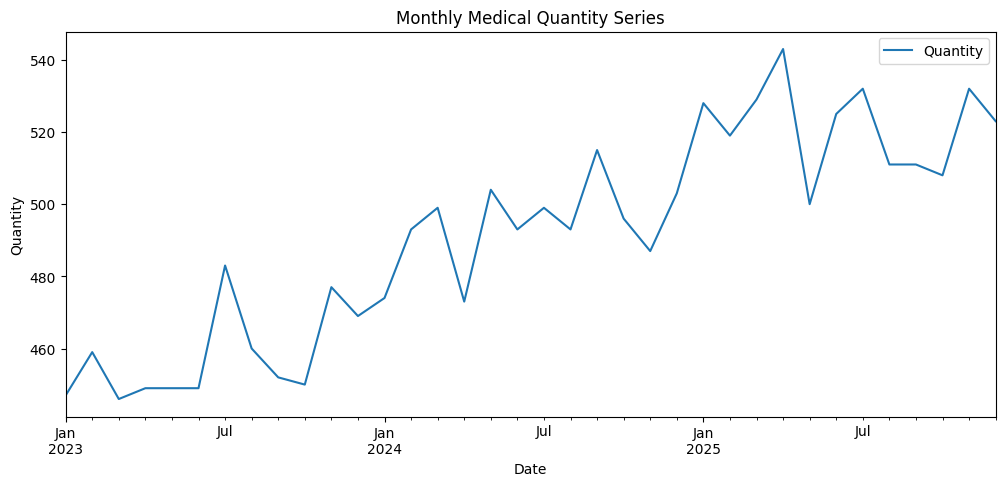

In [ ]:
# Plot the historical Quantity data to observe if it is stationary
df2.plot(y=['Quantity'], use_index=True, figsize=(12,5))
import matplotlib.pyplot as plt
plt.title('Monthly Medical Quantity Series')
plt.ylabel('Quantity')
plt.show()

# We will now find the best ARIMA model

In [ ]:
!pip install -q pmdarima
from pmdarima import auto_arima

# Run the automatic ARIMA parameter search on our 'Quantity' series
stepwise_fit = auto_arima(df2['Quantity'], trace=True, suppress_warnings=True)
stepwise_fit.summary()

Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=0.46 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=303.843, Time=0.03 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=298.558, Time=0.10 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=289.353, Time=0.07 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=302.376, Time=0.03 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=inf, Time=0.16 sec
 ARIMA(0,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=0.17 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=0.21 sec
 ARIMA(0,1,1)(0,0,0)[0]             : AIC=293.911, Time=0.03 sec

Best model:  ARIMA(0,1,1)(0,0,0)[0] intercept
Total fit time: 1.288 seconds


<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:                      y   No. Observations:                   36
Model:               SARIMAX(0, 1, 1)   Log Likelihood                -141.676
Date:                Thu, 12 Nov 2026   AIC                            289.353
Time:                        00:17:23   BIC                            294.019
Sample:                    01-01-2023   HQIC                           290.964
                         - 12-01-2025                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      2.3982      0.438      5.474      0.000       1.540       3.257
ma.L1         -0.8702      0.116     -7.507      0.000      -1.097      -0.643
sigma2       184.4785     62.448      2.954      0.003      62.082     306.875
===================================================================================
Ljung-Box (L1) (Q):                   0.09   Jarque-Bera (JB):                 1.41
Prob(Q):                              0.76   Prob(JB):                         0.50
Heteroskedasticity (H):               2.14   Skew:                             0.12
Prob(H) (two-sided):                  0.20   Kurtosis:                         2.05
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

# Split the data into Training (approx 80%) and Testing

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.model_selection import train_test_split

In [ ]:
# Since we only have 36 months of data, we split the last 6 months as the test set
train = df2.iloc[:-6]
test = df2.iloc[-6:]
print("Train shape:", train.shape, "Test shape:", test.shape)
display(test.head())

Train shape: (30, 1) Test shape: (6, 1)


,Quantity
Date,
2025-07-01,532
2025-08-01,511
2025-09-01,511
2025-10-01,508
2025-11-01,532


#Train the model on the training dataset

In [ ]:
from statsmodels.tsa.arima.model import ARIMA

# Train the ARIMA model on the training dataset using the best order (0,1,1) found by auto_arima
model = ARIMA(train['Quantity'], order=(0, 1, 1))
model_fit = model.fit()
print(model_fit.summary())

                               SARIMAX Results                                
Dep. Variable:               Quantity   No. Observations:                   30
Model:                 ARIMA(0, 1, 1)   Log Likelihood                -121.203
Date:                Thu, 12 Nov 2026   AIC                            246.407
Time:                        00:20:37   BIC                            249.142
Sample:                    01-01-2023   HQIC                           247.263
                         - 06-01-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.5403      0.153     -3.535      0.000      -0.840      -0.241
sigma2       246.8967     74.607      3.309      0.001     100.670     393.123
Ljung-Box (L1) (Q):                   1.28   Jarque-

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


#Make the prediction on the test data on the test data using the ARIMA model that we got previously and plot the prediction

In [ ]:
# Make prediction on the test dataset using the fitted ARIMA model
# We will forecast for the length of our test set (6 months)
TRpred = model_fit.forecast(steps=len(test))
TRpred.index = test.index
print("Predicted Values:")
print(TRpred)

Predicted Values:
Date
2025-07-01    520.658394
2025-08-01    520.658394
2025-09-01    520.658394
2025-10-01    520.658394
2025-11-01    520.658394
2025-12-01    520.658394
Name: predicted_mean, dtype: float64


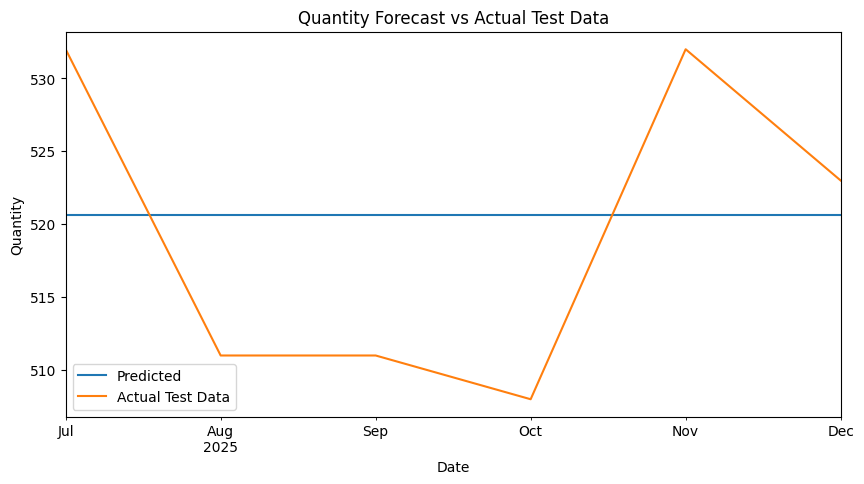

In [ ]:
import matplotlib.pyplot as plt

# Plot predictions vs actual test data
plt.figure(figsize=(10, 5))
TRpred.plot(label='Predicted', legend=True)
test['Quantity'].plot(label='Actual Test Data', legend=True)
plt.title('Quantity Forecast vs Actual Test Data')
plt.ylabel('Quantity')
plt.show()

# Find the Root Mean Square Error to find how good is the prediction

In [ ]:
from sklearn.metrics import mean_squared_error
from math import sqrt

# Calculate RMSE to evaluate accuracy
rmse = sqrt(mean_squared_error(test['Quantity'], TRpred))
print("Root Mean Squared Error (RMSE):", rmse)
print("Average Actual Test Quantity:", test['Quantity'].mean())

Root Mean Squared Error (RMSE): 10.07927951468008
Average Actual Test Quantity: 519.5


# Retrain the model on the full dataset and predict future values

In [ ]:
# Retrain the ARIMA model on the complete cleaned dataset (df2)
model2 = ARIMA(df2['Quantity'], order=(0, 1, 1))
model2_fit = model2.fit()
print(model2_fit.summary())

                               SARIMAX Results                                
Dep. Variable:               Quantity   No. Observations:                   36
Model:                 ARIMA(0, 1, 1)   Log Likelihood                -144.955
Date:                Thu, 12 Nov 2026   AIC                            293.911
Time:                        00:19:43   BIC                            297.022
Sample:                    01-01-2023   HQIC                           294.985
                         - 12-01-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.5579      0.133     -4.206      0.000      -0.818      -0.298
sigma2       229.1811     62.672      3.657      0.000     106.347     352.015
Ljung-Box (L1) (Q):                   0.88   Jarque-

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


## Predict and plot the variable for the rest of the months in August

In [ ]:
# Forecast the next 6 months into the future beyond the dataset (e.g., first half of 2026)
future_dates = pd.date_range(start='2026-01-01', periods=6, freq='MS')
forecast = model2_fit.forecast(steps=6)
forecast.index = future_dates
print("Future Forecast:")
print(forecast)

Future Forecast:
2026-01-01    521.863805
2026-02-01    521.863805
2026-03-01    521.863805
2026-04-01    521.863805
2026-05-01    521.863805
2026-06-01    521.863805
Freq: MS, Name: predicted_mean, dtype: float64


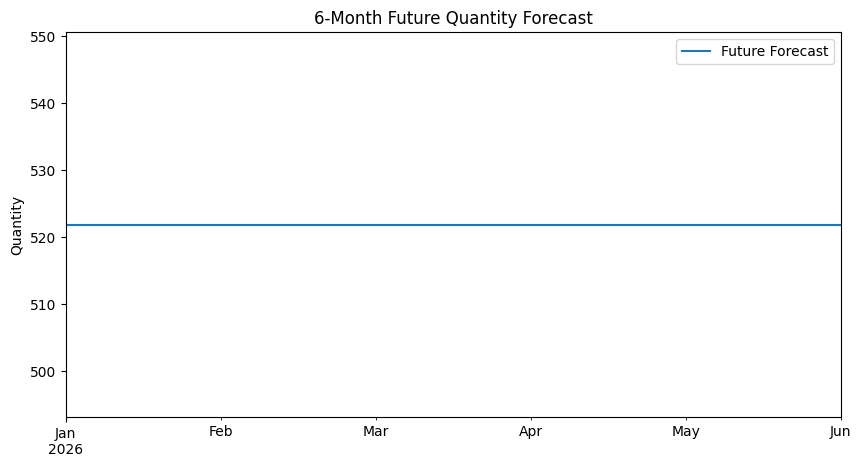

In [ ]:
# Plot the future forecast
plt.figure(figsize=(10, 5))
forecast.plot(legend=True, label='Future Forecast')
plt.title('6-Month Future Quantity Forecast')
plt.ylabel('Quantity')
plt.show()

In [ ]:
forecast.to_csv('Arima_Prediction.csv', encoding='utf-8')

In [ ]:
# Generate in-sample fitted predictions on the full dataset for comparison
forecast_full = model2_fit.predict(start=0, end=len(df2)-1, dynamic=False)
forecast_full.index = df2.index
print("Fitted Values:")
print(forecast_full.head())

Fitted Values:
Date
2023-01-01      0.000000
2023-02-01    446.942862
2023-03-01    453.869677
2023-04-01    450.088573
2023-05-01    449.594600
Name: predicted_mean, dtype: float64


In [ ]:
forecast_full.to_csv('Arima_PredictionFull.csv', encoding='utf-8')